# ML Assignment-2

### Name: Madhavakumar D
### BITS ID: 2026AJ05463
### Date: 8th Nov 2026

This is the Jupyter Notebook for training the Binary Classification models.


In [20]:
import sys
print(sys.executable)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

import warnings
warnings.filterwarnings("ignore")

/opt/homebrew/opt/python@3.11/bin/python3.11


In [21]:
df = pd.read_excel(
    "default of credit card clients.xls",
    header=1,
    engine="xlrd"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (30000, 25)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [22]:
print(df.columns.tolist())

df.info()

df.describe()

print(df.isnull().sum().sum())

target = "default payment next month"

print(df[target].value_counts())
print("\nPercentage distribution:")
print(df[target].value_counts(normalize=True) * 100)

['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9  

Dataset Shape: (30000, 24)


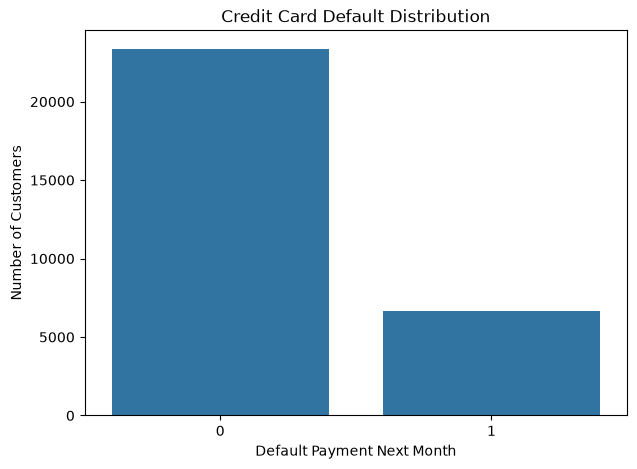

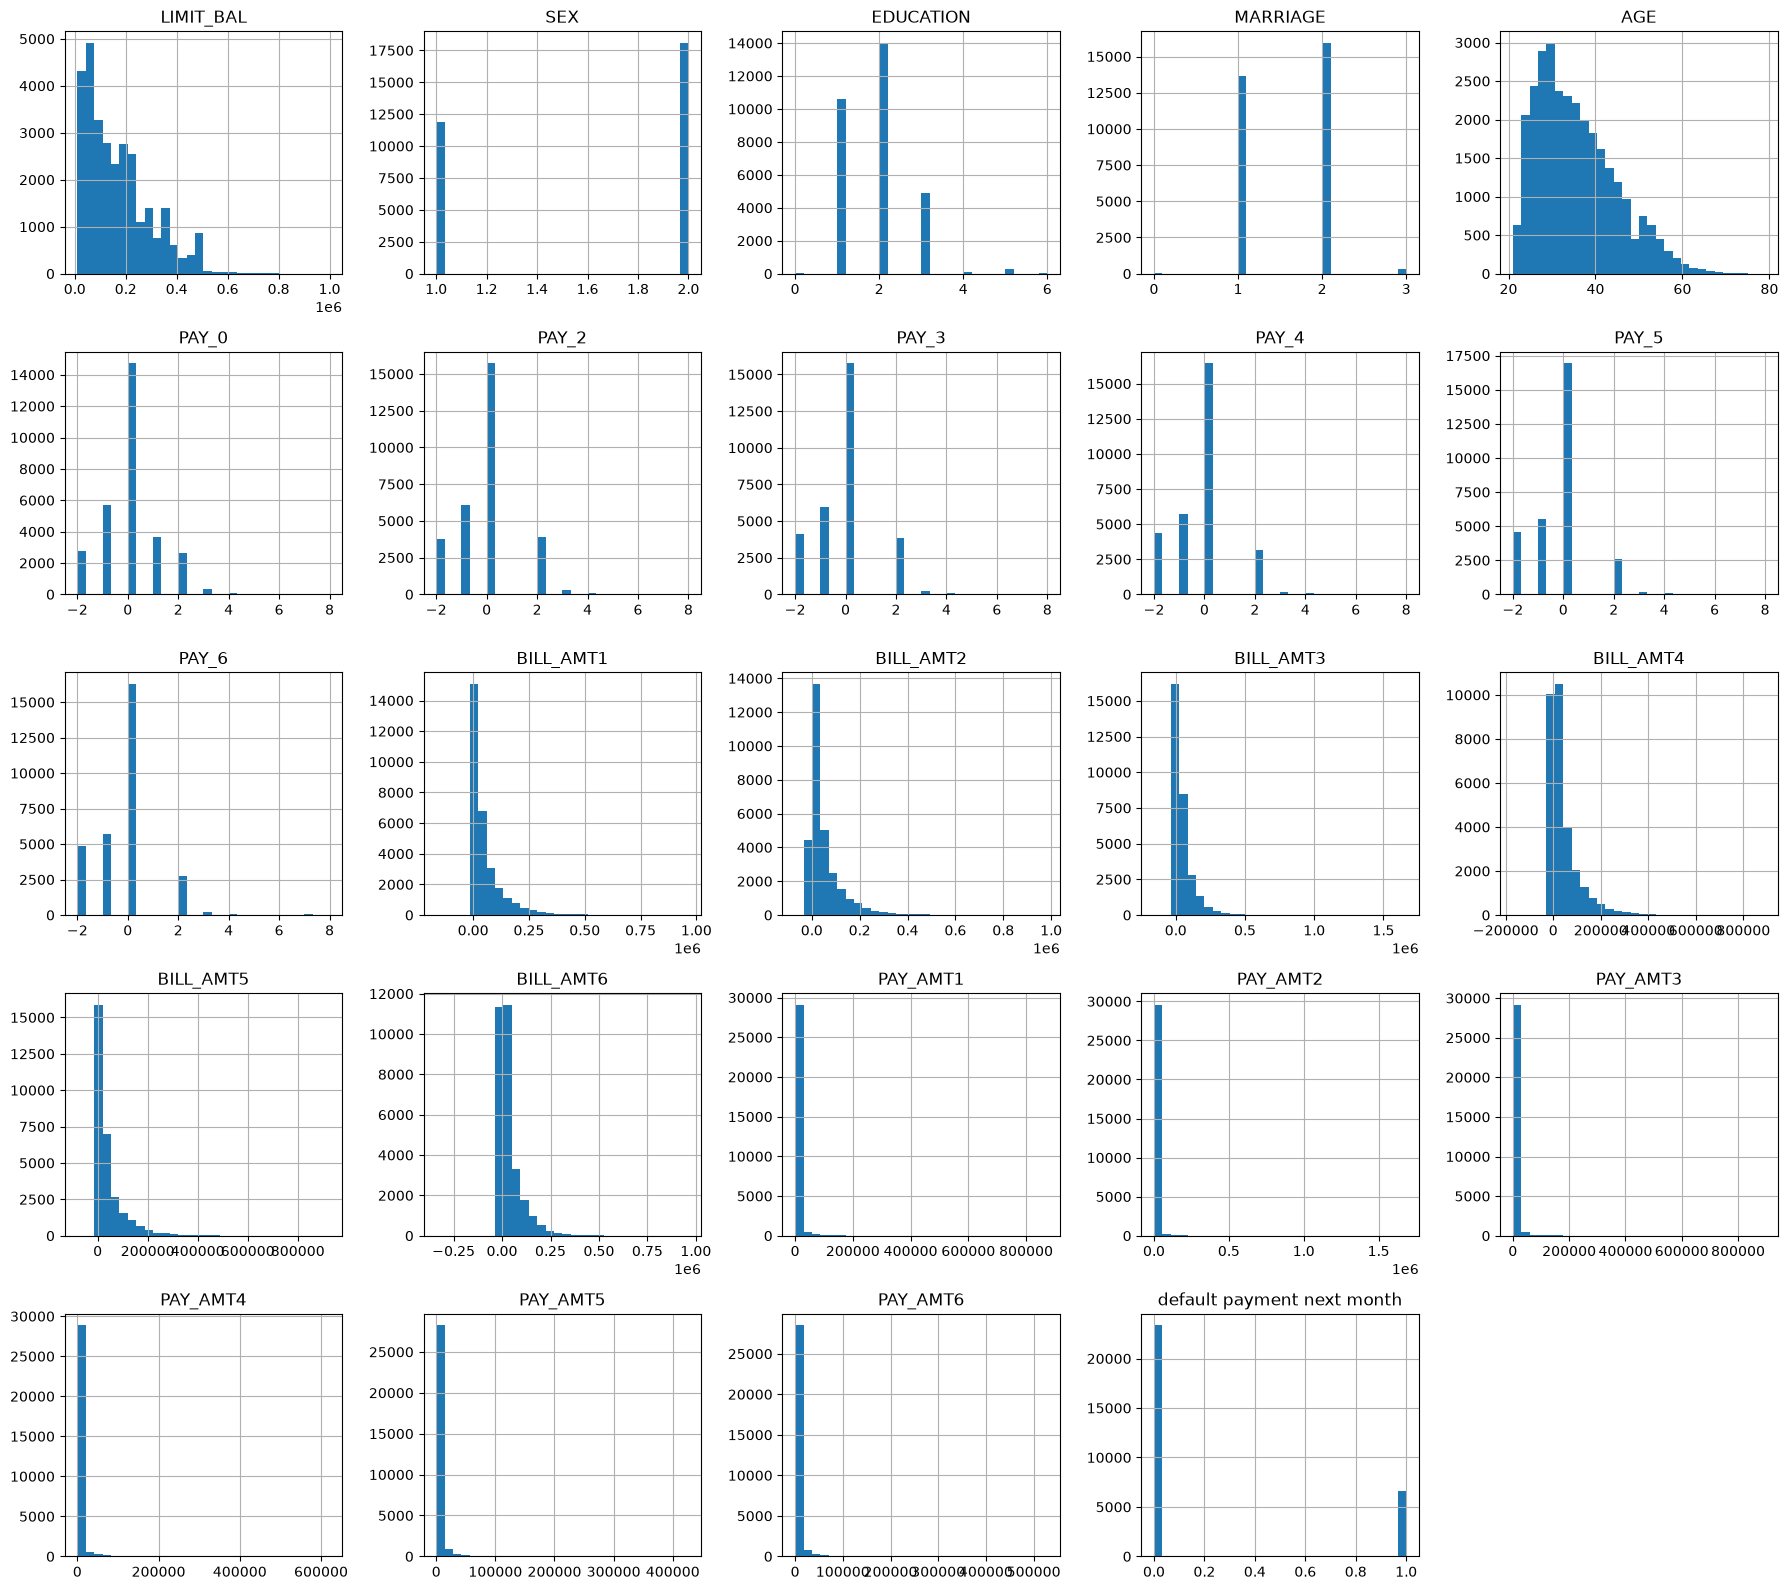

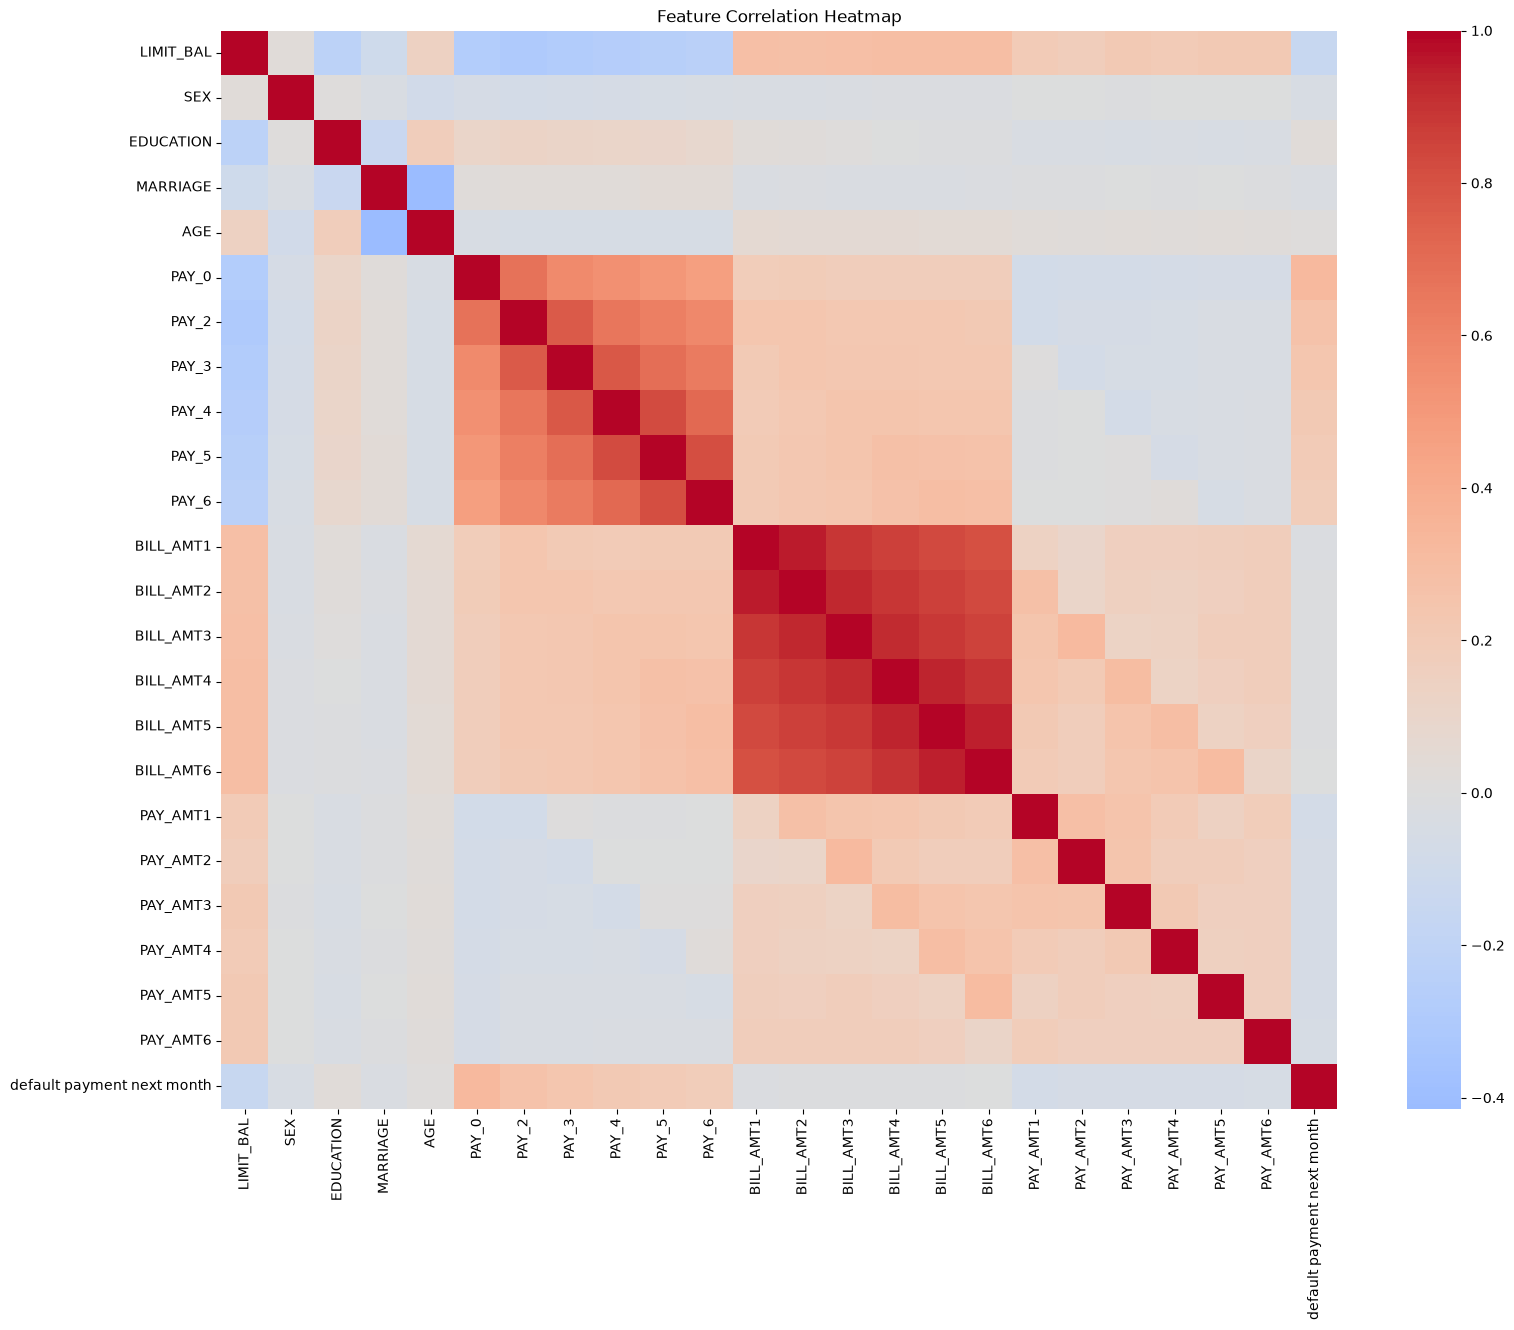

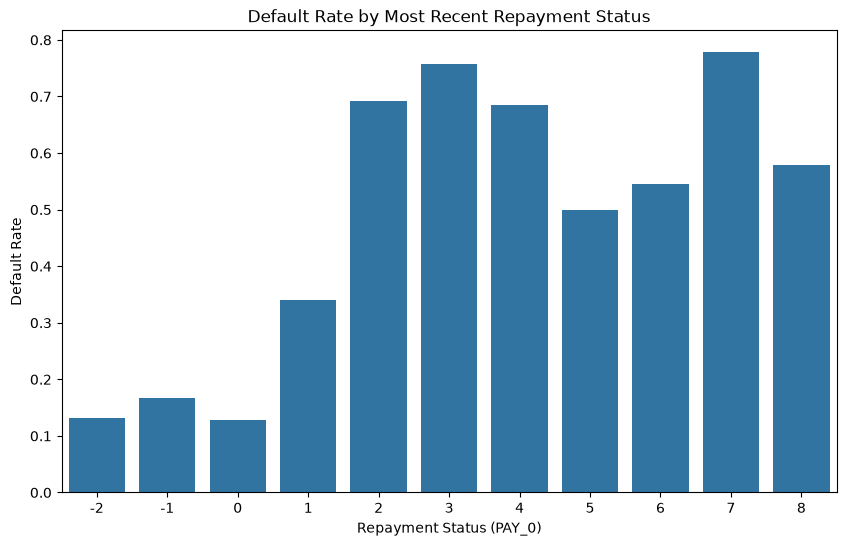

In [23]:
df = df.drop(columns=["ID"])
print("Dataset Shape:", df.shape)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="default payment next month")
plt.title("Credit Card Default Distribution")
plt.xlabel("Default Payment Next Month")
plt.ylabel("Number of Customers")
plt.show()

df.hist(figsize=(18, 16), bins=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(18, 14))
sns.heatmap(
    df.corr(),
    cmap="coolwarm",
    center=0,
    annot=False
)
plt.title("Feature Correlation Heatmap")
plt.show()

plt.figure(figsize=(10, 6))
sns.barplot(
    data=df,
    x="PAY_0",
    y="default payment next month",
    errorbar=None
)
plt.title("Default Rate by Most Recent Repayment Status")
plt.xlabel("Repayment Status (PAY_0)")
plt.ylabel("Default Rate")
plt.show()

In [24]:
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["default payment next month"])
y = df["default payment next month"]

# Categorical and numerical features
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
numerical_features = [col for col in X.columns if col not in categorical_features]

# Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Target Distribution:")
print(y_test.value_counts(normalize=True))

Training Features: (24000, 23)
Testing Features: (6000, 23)

Training Target Distribution:
default payment next month
0    0.778792
1    0.221208
Name: proportion, dtype: float64

Testing Target Distribution:
default payment next month
0    0.778833
1    0.221167
Name: proportion, dtype: float64


In [25]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features),
        ("numerical", StandardScaler(), numerical_features)
    ]
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel="rbf", random_state=42)
}

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)

results = []
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    # Get prediction scores for AUC
    if hasattr(pipeline, "predict_proba"):
        y_score = pipeline.predict_proba(X_test)[:, 1]
    else:
        y_score = pipeline.decision_function(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": roc_auc_score(y_test, y_score),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

    trained_models[name] = pipeline

    print(f"{name} training completed.")


results_df = pd.DataFrame(results)
results_df = results_df.set_index("Model").round(4)
results_df

Logistic Regression training completed.
Decision Tree training completed.
KNN training completed.
Naive Bayes training completed.
SVM training completed.


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Model,,,,,,
Logistic Regression,0.8088,0.7100,0.6923,0.2442,0.3610,0.3302
Decision Tree,0.7155,0.6040,0.3684,0.4009,0.3840,0.1997
KNN,0.7948,0.7039,0.5561,0.3587,0.4361,0.3292
Naive Bayes,0.2903,0.7240,0.2340,0.9714,0.3771,0.1034
SVM,0.8163,0.7201,0.6662,0.3399,0.4501,0.3824


In [26]:
from sklearn.metrics import confusion_matrix, classification_report

for name, pipeline in trained_models.items():

    y_pred = pipeline.predict(X_test)

    print("\n", "=" * 55)
    print(name)
    print("=" * 55)

    print("\nConfusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No Default", "Default"]
    ))



Logistic Regression

Confusion Matrix:
[[4529  144]
 [1003  324]]

Classification Report:
              precision    recall  f1-score   support

  No Default       0.82      0.97      0.89      4673
     Default       0.69      0.24      0.36      1327

    accuracy                           0.81      6000
   macro avg       0.76      0.61      0.62      6000
weighted avg       0.79      0.81      0.77      6000


Decision Tree

Confusion Matrix:
[[3761  912]
 [ 795  532]]

Classification Report:
              precision    recall  f1-score   support

  No Default       0.83      0.80      0.82      4673
     Default       0.37      0.40      0.38      1327

    accuracy                           0.72      6000
   macro avg       0.60      0.60      0.60      6000
weighted avg       0.72      0.72      0.72      6000


KNN

Confusion Matrix:
[[4293  380]
 [ 851  476]]

Classification Report:
              precision    recall  f1-score   support

  No Default       0.83      0.92      0

In [27]:
import os
import joblib

os.makedirs("model", exist_ok=True)

for name, pipeline in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"
    joblib.dump(pipeline, os.path.join("model", filename))

print("All five models saved successfully.")

All five models saved successfully.


In [28]:
# Combine test features and actual target
test_data = X_test.copy()
test_data["default payment next month"] = y_test

# Save as CSV
test_data.to_csv("test_data.csv", index=False)

print("Test data saved successfully.")
print("Shape:", test_data.shape)

test_data.head()

Test data saved successfully.
Shape: (6000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
6907,50000,1,2,2,46,-1,-1,-1,-1,0,...,2650,3320,2764,26060,0,3472,2320,1764,2841,0
24575,150000,1,1,1,31,-1,-1,-2,-2,-2,...,0,0,11694,0,0,0,0,11694,30000,0
26766,50000,1,2,2,25,0,0,0,0,0,...,49949,50479,50702,1800,1844,2200,2000,1800,2038,0
2156,290000,2,1,2,25,0,0,0,0,0,...,248801,241983,230925,15000,10500,10000,15000,7844,23333,1
3179,500000,2,2,1,27,-2,-2,-2,-2,-2,...,10000,10000,10000,9983,13587,10000,10000,10000,25304,0
